# Feature normalization

The 12 features live on very different scales: a standard deviation can range from 0.003 to 7,
while a correlation stays between 0 and 1. A model that adds up evidence from all features
would be dominated by the largest numbers. This notebook puts the features on a common scale.

1. **Logarithm** for the features that span several orders of magnitude or are stretched by a
   few extreme values: the two standard deviations (`log10`) and the two dominant frequencies
   (`log1p`, the logarithm of 1 plus the value, which is safe close to zero). Without it, a
   Z-score would squeeze Still, Standing and Walking together because Jumping stretches the scale.
2. **Z-score** for all 12 features: subtract the average and divide by the standard deviation.
   Every feature then has an average of 0 and a typical spread of 1.

The average and spread are computed on the training windows only and saved to a file. Any new
recording must be scaled with these saved numbers, never with its own average and spread.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FEATURES_DIR = Path("../data/features")
FIGURES_DIR = Path("../figures")
LOG10_COLUMNS = ["acc_std", "gyro_std"]
LOG1P_COLUMNS = ["acc_dom_freq", "gyro_dom_freq"]
FLOOR = 1e-6  # keeps log10 defined if a window is perfectly flat

features = pd.read_csv(FEATURES_DIR / "window_features.csv")
FEATURE_COLUMNS = [c for c in features.columns if c not in ("file", "activity")]
len(features), FEATURE_COLUMNS

(92,
 ['acc_std',
  'acc_corr',
  'acc_jerk_ratio',
  'acc_dom_freq',
  'acc_low_freq_share',
  'acc_spec_centroid',
  'gyro_std',
  'gyro_corr',
  'gyro_jerk_ratio',
  'gyro_dom_freq',
  'gyro_low_freq_share',
  'gyro_spec_centroid'])

## Normalization functions

In [2]:
def log_transform(table):
    """Apply log10 to the strength features and log1p to the dominant frequencies."""
    out = table.copy()
    for column in LOG10_COLUMNS:
        out[column] = np.log10(np.maximum(table[column], FLOOR))
    for column in LOG1P_COLUMNS:
        out[column] = np.log1p(table[column])
    return out


def fit_scaler(table):
    """Average and standard deviation of every feature, after the log transform."""
    transformed = log_transform(table)[FEATURE_COLUMNS]
    return {
        "mean": transformed.mean().to_dict(),
        "std": transformed.std(ddof=0).to_dict(),
    }


def apply_scaler(table, scaler):
    """Log-transform a feature table and standardize it with a fitted scaler."""
    transformed = log_transform(table)
    for column in FEATURE_COLUMNS:
        transformed[column] = (transformed[column] - scaler["mean"][column]) / scaler["std"][column]
    return transformed

## Fit on the training windows and save

All 92 windows are training data: the unseen test recordings are separate. The fitted average
and spread are saved so the test recordings can be scaled with the same numbers.

In [3]:
scaler = fit_scaler(features)
(FEATURES_DIR / "scaler.json").write_text(json.dumps(scaler, indent=2))

normalized = apply_scaler(features, scaler)
normalized.to_csv(FEATURES_DIR / "window_features_normalized.csv", index=False)

check = pd.DataFrame({
    "mean": normalized[FEATURE_COLUMNS].mean(),
    "std": normalized[FEATURE_COLUMNS].std(ddof=0),
}).T.round(6)
assert np.allclose(check.loc["mean"], 0, atol=1e-9) and np.allclose(check.loc["std"], 1, atol=1e-9)
assert not normalized[FEATURE_COLUMNS].isna().any().any()
check

,acc_std,acc_corr,acc_jerk_ratio,acc_dom_freq,acc_low_freq_share,acc_spec_centroid,gyro_std,gyro_corr,gyro_jerk_ratio,gyro_dom_freq,gyro_low_freq_share,gyro_spec_centroid
mean,0.0,-0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Does the logarithm help?

Skewness measures how much a few huge values stretch one side of a feature: 0 means symmetric.
The table compares it before and after the log transform for the four transformed features.

In [4]:
columns = LOG10_COLUMNS + LOG1P_COLUMNS
pd.DataFrame({
    "skewness before": features[columns].skew(),
    "skewness after": log_transform(features)[columns].skew(),
}).round(2)

,skewness before,skewness after
acc_std,1.50,-0.30
gyro_std,0.68,-0.60
acc_dom_freq,4.80,0.83
gyro_dom_freq,2.18,1.06


## Effect on the spacing of the activities

Each dot is one window. Without the logarithm, the Z-score of the accelerometer standard
deviation leaves Still, Standing and Walking close together; with it, the four activities
are spread out evenly.

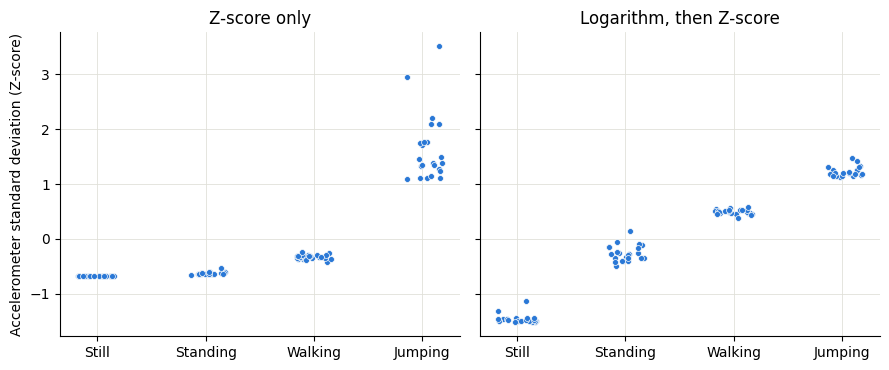

In [5]:
ORDER = ["Still", "Standing", "Walking", "Jumping"]
raw_z = (features["acc_std"] - features["acc_std"].mean()) / features["acc_std"].std(ddof=0)
panels = [("Z-score only", raw_z), ("Logarithm, then Z-score", normalized["acc_std"])]

rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, (title, values) in zip(axes, panels):
    for position, activity in enumerate(ORDER):
        chosen = values[features["activity"] == activity]
        ax.scatter(position + rng.uniform(-0.18, 0.18, len(chosen)), chosen,
                   s=18, color="#2a78d6", edgecolors="#fcfcfb", linewidths=0.5)
    ax.set_xticks(range(len(ORDER)), ORDER)
    ax.set_title(title)
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Accelerometer standard deviation (Z-score)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "normalization_effect.png", dpi=200, bbox_inches="tight")
plt.show()